In [1]:
import sys
import os


sys.path.insert(0, os.path.abspath("."))
sys.path.append(os.path.abspath("../../../"))

In [2]:
from desc import set_device
set_device("gpu")

As mentioned in [DESC Documentation on performance tips](https://desc-docs.readthedocs.io/en/latest/performance_tips.html), one can use compilation cache directory to reduce the compilation overhead time. Uncomment the next code block to take advantage of the cache.

Note: One needs to create jax-caches folder manually.

In [3]:
import jax

jax.config.update("jax_compilation_cache_dir", "../jax-caches")
jax.config.update("jax_persistent_cache_min_entry_size_bytes", -1)
jax.config.update("jax_persistent_cache_min_compile_time_secs", 0)

In [4]:
import numpy as np
from desc.coils import (
    CoilSet,
    FourierPlanarCoil,
    MixedCoilSet,
    initialize_modular_coils,
    initialize_saddle_coils,
)
import desc.examples
from desc.equilibrium import Equilibrium
from desc.plotting import plot_2d, plot_3d, plot_coils, plot_comparison
from desc.grid import LinearGrid
from desc.objectives import (
    ObjectiveFunction,
    CoilCurvature,
    CoilLength,
    CoilTorsion,
    CoilSetLinkingNumber,
    CoilSetMinDistance,
    PlasmaCoilSetMinDistance,
    SurfaceQuadraticFlux,
    #SurfaceMatch,
    ToroidalFlux,
    Volume,
    FixSumCoilCurrent,
    FixParameters,
    get_fixed_boundary_constraints,
    ForceBalance,
    Elongation
)
from desc.geometry import FourierRZToroidalSurface
from desc.coils import CoilSet
from desc.optimize import Optimizer
from desc.integrals import compute_B_plasma
from scipy.optimize import fsolve, minimize
from desc.magnetic_fields import field_line_integrate
from desc.plotting import *
from matplotlib import pyplot as plt
import time
import plotly.express as px
import plotly.io as pio
from desc.io import load
# This ensures Plotly output works in multiple places:
# plotly_mimetype: VS Code notebook UI
# notebook: "Jupyter: Export to HTML" command in VS Code
# See https://plotly.com/python/renderers/#multiple-renderers
pio.renderers.default = "plotly_mimetype+notebook"

## Coil Optimization Metrics

Two main figures of merit regarding the quality of the coil optimization in recreating the equilibrium are the average normalized magnetic field and Poincare plot from the coils. The average normalized magnetic field is a measure of how well the coils' field (plus the plasma field if it is finite beta) recreates last closed flux surface of the target equilibrium and is given as 
$$
\frac{\left<|\mathbf{B}_{\text{total}}\cdot \mathbf{\hat{n}}|\right>}{\left<|\mathbf{B}_{\text{total}}|\right>}
$$
where $\mathbf{\hat{n}}$ is the normal vector to the equilibrium's last closed flux surface and $\mathbf{B}_{\text{total}} = \mathbf{B}_{\text{coils}} + \mathbf{B}_{\text{plasma currents}}$. Field traces are also significant for vacuum equilibria because they visually show the quality of the coil field in recreating the equilibrium vacuum flux surfaces.

These two metrics are calculated in functions below.

In [5]:
def compute_average_normalized_field(
    field, eq, vacuum=False, chunk_size=None, B_plasma_chunk_size=None
):
    if B_plasma_chunk_size is None:
        B_plasma_chunk_size = chunk_size
    grid = LinearGrid(M=80, N=80, NFP=eq.NFP)
    if vacuum:
        # we can avoid the expensive plasma contribution calculation if we
        # just pass in the surface instead of the Equilibrium!
        Bn, surf_coords = field.compute_Bnormal(
            eq.surface,
            eval_grid=grid,
            chunk_size=chunk_size,
            B_plasma_chunk_size=B_plasma_chunk_size,
        )
    else:
        Bn, surf_coords = field.compute_Bnormal(
            eq,
            eval_grid=grid,
            chunk_size=chunk_size,
            B_plasma_chunk_size=B_plasma_chunk_size,
        )
    normalizing_field_vec = field.compute_magnetic_field(surf_coords)
    if not vacuum:
        # add plasma field to the normalizing field
        normalizing_field_vec += compute_B_plasma(
            eq, eval_grid=grid, chunk_size=B_plasma_chunk_size
        )
    normalizing_field = np.mean(np.linalg.norm(normalizing_field_vec, axis=1))
    return np.mean(np.abs(Bn)) / normalizing_field


def plot_field_lines(field, eq):
    # for starting locations we'll pick positions on flux surfaces on the outboard midplane
    grid_trace = LinearGrid(rho=np.linspace(0, 1, 9))
    r0 = eq.compute("R", grid=grid_trace)["R"]
    z0 = eq.compute("Z", grid=grid_trace)["Z"]
    fig, ax = desc.plotting.plot_surfaces(eq)
    fig, ax = desc.plotting.poincare_plot(
        field,
        r0,
        z0,
        NFP=eq.NFP,
        ax=ax,
        color="k",
        size=1,
    )
    return fig, ax

## Find the axis


In [6]:
field = CoilSet.load("QFM_coilset_tqB2p1.h5")
eq = Equilibrium.load("eq_NFP2_A+9.0_tor+0.0_mr+0.10_shift+0.00_wd+0.00_elong+3.00_wellwt+2.0_vacuum_final2.h5")

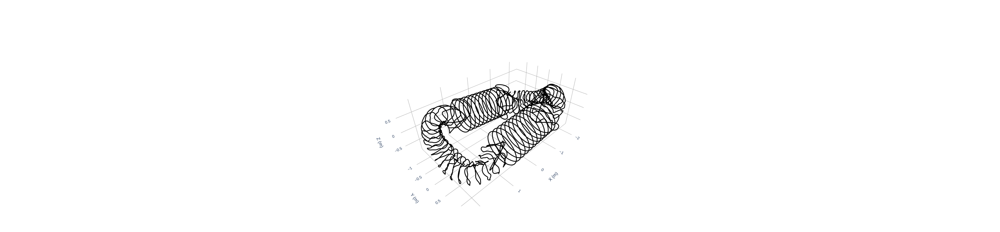

In [7]:
plot_coils(field)

In [7]:
nturns = 1
# npoints_per_turn = 1
# phi_full = np.linspace(0, 2 * np.pi * nturns, nturns * npoints_per_turn+1)
# grid_trace = LinearGrid(rho=np.array([0.]), theta=np.array([0.]), zeta=np.array([0.]))
# def fun_root(x):
#    r0 = x + eq.compute("R", grid=grid_trace)["R"][0]
#    z0 = [0.]
#    r, z = field_line_integrate(
#        r0, z0, phis=phi_full, field=field, bounds_R=(0.65, 2.65), bounds_Z=(-1.0, 1.0)
#    )
#    return (r[-1] - r[0])
# x_solution = fsolve(fun_root, 1.0)[0]

In [8]:
x_solution = 1.0216246367096462

In [20]:
grid_trace = LinearGrid(rho=np.array([0.]), theta=np.array([0.]), zeta=np.array([0.]))
#r0 = [x_solution + eq.compute("R", grid=grid_trace)["R"][0].item()]
r0 =  [1.0216246367096462 + eq.compute("R", grid=grid_trace)["R"][0].item()]
z0 = [0.]
#print(r0, z0)
nturns = 1
npoints_per_turn = 128
phi_full = np.linspace(0, 2 * np.pi * nturns, nturns * npoints_per_turn+1)
r, z = field_line_integrate(
   r0, z0, phis=phi_full, field=field, bounds_R=(0.65, 2.65), bounds_Z=(-1.0, 1.0)
)


data = np.array([r.flatten(), phi_full, z.flatten()]).T
curve = FourierRZCurve.from_values(coords=data, N=10)

#import pdb
#pdb.set_trace()

#curve.save("magnetic_axis_N10.h5")

theta = np.linspace(0., 2*np.pi, 256)
theta_2D, phi_2D = np.meshgrid(theta, phi_full, indexing="ij")

r = r.flatten()
z = z.flatten()
r = r[None, :] + 0.02*np.cos(theta_2D)
z = z[None, :] + 2*0.02*np.sin(theta_2D)
print(r.shape, phi_2D.shape, z.shape)
coords = np.vstack([r.flatten(), phi_2D.flatten(), z.flatten()]).T

M0 = 10
N0 = 12
surf0 = FourierRZToroidalSurface.from_values(coords=coords, theta=theta_2D.flatten(), M=M0, N=N0, NFP=2, sym=True, rcond=1e-7)


(256, 129) (256, 129) (256, 129)


/pscratch/sd/r/rgaur/DESC2/DESC/desc/geometry/surface.py:152: UserWarning:

Left handed coordinates detected, switching sign of theta. To avoid this warning in the future, switch the sign of all modes with m<0. You may also need to switch the sign of iota or current profiles.



## Separating the shaping and non-shaping coils 

In [10]:
#field[1]
list1 = []
for i in range(10):
    list1.append(field[1][i]) 
coilset1 = CoilSet(list1, NFP=eq.NFP, sym=True, check_intersection=True)

list2 = []
list21 = []

shaping_coil = field[2][0]
#shaping_coil.change_resolution(N=1)
shaping_coil = shaping_coil.to_FourierXYZ(N=2)
#shaping_coil.to_FourierPlanar(basis="xyz")
#shaping_coil = shaping_coil.to_FourierXYZ(N=1)
shaping_coil1 = shaping_coil.copy()
#shaping_coil1 = shaping_coil1.to_FourierXY(basis="xyz")
#shaping_coil1.center = field[2][0].center
#shaping_coil1.normal = field[2][0].normal
#shaping_coil1.change_resolution(N=2)

# shaping_coil2 = field[2][2].copy()
# shaping_coil2.change_resolution(N=0)
# shaping_coil2 = shaping_coil2.to_FourierXY(basis="xyz")
# shaping_coil2.center = field[2][2].center
# shaping_coil2.normal = field[2][2].normal
# shaping_coil2.change_resolution(N=2)

list21.append(shaping_coil1)
#list21.append(shaping_coil2)
coilset21 = CoilSet(list21, NFP=eq.NFP, sym=True, check_intersection=True)


list2.append(shaping_coil) 
coilset2 = CoilSet(list2, NFP=eq.NFP, sym=True, check_intersection=True)

list3 = []
for i in np.arange(2, 12, 2):
    list3.append(field[2][i]) 
coilset3 = CoilSet(list3, NFP=eq.NFP, sym=True, check_intersection=True)

list4 = []
list4.append(field[2][12])
coilset4 = CoilSet(list4, sym=True, check_intersection=True)

#list5 = []
#list4.append(field[2][12]) 
#coilset5 = CoilSet.from_symmetry(list5, NFP=True, check_intersection=True)


#coilset1 = CoilSet.from_symmetry([field[0][:10], field[1][:10]], NFP=eq.NFP, sym=True, check_intersection=True)
#for coil in field[1]:
#    print(coil)

#field1 = MixedCoilSet([coilset1, coilset2, coilset3, coilset4]) 

field1 = MixedCoilSet([coilset1, coilset2, coilset3, coilset4]) 
field2 = MixedCoilSet([coilset1.copy(), coilset21, coilset3.copy(), coilset4.copy()]) 

fig = plot_coils(field1)
fig.show()
plt.figure()
fig = plot_coils(field2)
fig.show()

#field[1][2]

<Figure size 432x288 with 0 Axes>

In [11]:
#dir(shaping_coil1)
shaping_coil.X_n

Array([5.55111512e-17, 1.94289029e-16, 1.00000000e+00, 4.58944152e-02,
       2.91433544e-16], dtype=float64)

/pscratch/sd/r/rgaur/DESC2/DESC/desc/utils.py:572: UserWarning:

Unequal number of field periods for grid 1 and basis 2.



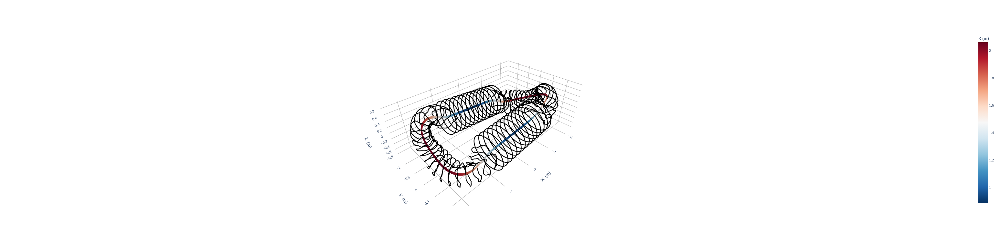

In [12]:
#plot_boundary(surf0)
fig = plot_coils(field1)
fig = plot_3d(surf0, name="R", fig=fig)
fig.show()

Building objective: Surface Quadratic Flux
Precomputing transforms
Timer: Precomputing transforms = 680 ms
Building objective: toroidal-flux
Precomputing transforms


/global/homes/r/rgaur/.conda/envs/desc-env2/lib/python3.12/site-packages/jax/_src/compiler.py:799: UserWarning:

Error reading persistent compilation cache entry for 'jit_multiply': error: Error -5 while decompressing data: incomplete or truncated stream



Timer: Precomputing transforms = 598 ms
Timer: Objective build = 2.28 sec
Number of parameters: 1073
Number of objectives: 3186
Timer: Initializing the optimization = 2.36 sec

Starting optimization
Using method: lsq-exact
Solver options:
------------------------------------------------------------
Maximum Function Evaluations       : 501
Maximum Allowed Total Δx Norm      : inf
Scaled Termination                 : True
Trust Region Method                : qr
Initial Trust Radius               : 2.218e+00
Maximum Trust Radius               : inf
Minimum Trust Radius               : 2.220e-16
Trust Radius Increase Ratio        : 2.000e+00
Trust Radius Decrease Ratio        : 2.500e-01
Trust Radius Increase Threshold    : 7.500e-01
Trust Radius Decrease Threshold    : 2.500e-01
------------------------------------------------------------ 

   Iteration     Total nfev        Cost      Cost reduction    Step norm     Optimality   
       0              1          7.566e+02                 

/pscratch/sd/r/rgaur/DESC2/DESC/desc/utils.py:572: UserWarning:

Unequal number of field periods for grid 1 and basis 2.



<Figure size 432x288 with 0 Axes>

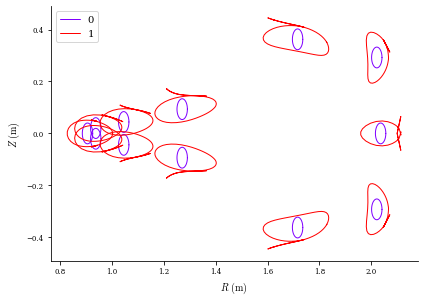

In [13]:
surf0.change_resolution(M=14, N=18)

surf0.rho = 1.0
surf0.iota = -0.512
surf0.G = 0.1

qflux = SurfaceQuadraticFlux(
    surf0,
    field1,
    eval_grid=LinearGrid(M=24, N=32, NFP=surf0.NFP),
    field_fixed=True,  # field is not being optimized
    bs_chunk_size=10,
    weight=1e-1
)

target_psi = -0.050
tflux = ToroidalFlux(
    surf0,
    field1,
    target=target_psi,  # the same toroidal flux as used in the free bdry eq
    eq_fixed=False,  # we will allow the thing passed in (QFM surface in this case) to vary
    field_fixed=True,  # field is not being optimized, so we fix it
    weight=1e3
)

#target_volume = 0.2
#volm = Volume(surface0, target=target_volume, weight=5e1)

obj = ObjectiveFunction((qflux, tflux))
#obj = ObjectiveFunction((qflux,))
#obj = ObjectiveFunction((qflux, volm))

#opt = Optimizer("lsq-auglag")
opt = Optimizer("lsq-exact")
#opt = Optimizer("proximal-lsq-exact")

constraints=(tflux,)

(qfm_surf1,), _ = opt.optimize(
    surf0,
    objective=obj,
    #constraints=constraints,
    ftol=5e-4,
    maxiter=100,
    verbose=3,
    copy=True,
)

#print(qfm_surf1.iota, qfm_surf1.G)

fig = plot_coils(field1)
fig = plot_3d(qfm_surf1, name="R", fig=fig)
#fig.write_html("test0.html")

plt.figure()
plot_boundaries([surf0, qfm_surf1], phi=12)
plt.savefig("test.png", dpi=400)

(<Figure size 2880x2880 with 1 Axes>,
 <Axes: xlabel='$R ~(\\mathrm{m})$', ylabel='$Z ~(\\mathrm{m})$'>)

<Figure size 432x288 with 0 Axes>

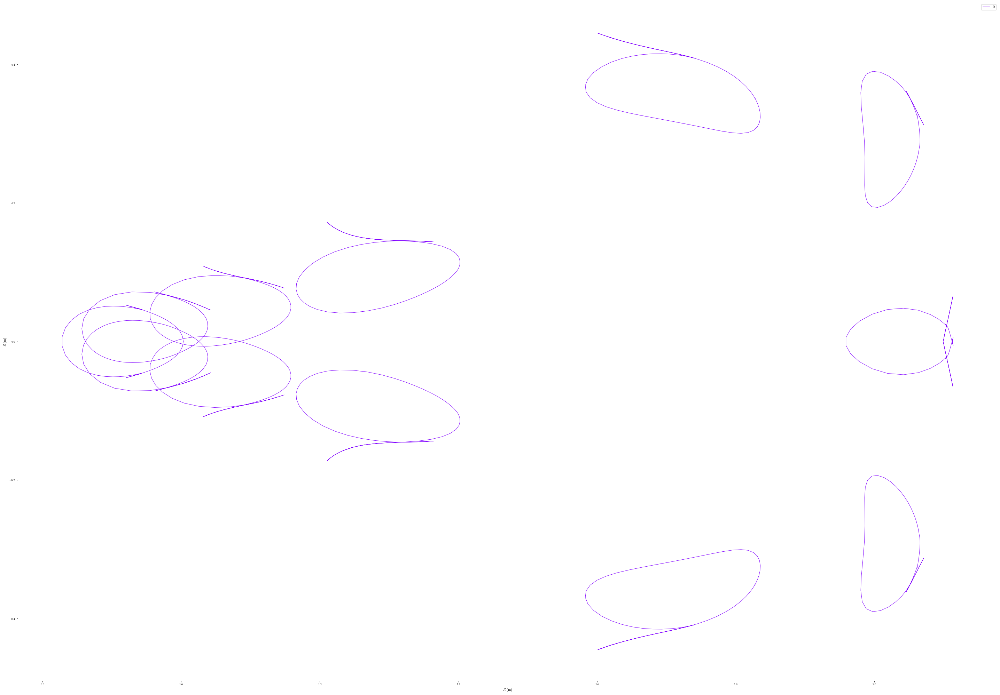

In [15]:
qfm_surf1.save("target_QFM_surface_hres.h5")
plt.figure()
plot_boundaries([qfm_surf1], phi=12, figsize=(40, 40))

## Re-sampling and re=fitting to the initial QFM surface for smoothness

In [23]:
phi_full = np.linspace(0, 2*np.pi, 96)
axis_data = curve.compute(["R", "Z"], grid=LinearGrid(zeta=phi_full))
r_axis = axis_data["R"]
z_axis = axis_data["Z"]

qfm_surf_grid = LinearGrid(rho=1., M=64, zeta=phi_full)
qfm_surf_data = qfm_surf1.compute(["R", "Z"], grid=qfm_surf_grid)
r = qfm_surf_data["R"]
z = qfm_surf_data["Z"]
#theta_arctan = np.arctan2(z-z_axis, r-r_axis)

/pscratch/sd/r/rgaur/DESC2/DESC/desc/utils.py:572: UserWarning:

Unequal number of field periods for grid 1 and basis 2.

/pscratch/sd/r/rgaur/DESC2/DESC/desc/utils.py:572: UserWarning:

Unequal number of field periods for grid 1 and basis 2.



In [24]:
r

(12384,)

In [20]:
# surf0.change_resolution(M=12, N=16)

# surf0.rho = 1.0
# surf0.iota = -0.512
# surf0.G = 0.1

# qflux = SurfaceQuadraticFlux(
#     surf0,
#     field2,
#     eval_grid=LinearGrid(M=24, N=32, NFP=surf0.NFP),
#     field_fixed=True,  # field is not being optimized
#     bs_chunk_size=10,
#     weight=1e-1
# )

# target_psi = -0.050
# tflux = ToroidalFlux(
#     surf0,
#     field2,
#     target=target_psi,  # the same toroidal flux as used in the free bdry eq
#     eq_fixed=False,  # we will allow the thing passed in (QFM surface in this case) to vary
#     field_fixed=True,  # field is not being optimized, so we fix it
#     weight=1e3
# )

# #target_volume = 0.2
# #volm = Volume(surface0, target=target_volume, weight=5e1)

# obj = ObjectiveFunction((qflux, tflux))
# #obj = ObjectiveFunction((qflux,))
# #obj = ObjectiveFunction((qflux, volm))

# #opt = Optimizer("lsq-auglag")
# opt = Optimizer("lsq-exact")
# #opt = Optimizer("proximal-lsq-exact")

# constraints=(tflux,)

# (qfm_surf2,), _ = opt.optimize(
#     surf0,
#     objective=obj,
#     #constraints=constraints,
#     ftol=5e-4,
#     maxiter=100,
#     verbose=3,
#     copy=True,
# )

# #print(qfm_surf1.iota, qfm_surf1.G)

# fig = plot_coils(field2)
# fig = plot_3d(qfm_surf2, name="R", fig=fig)
# #fig.write_html("test0.html")

# plt.figure()
# plot_boundaries([qfm_surf1, qfm_surf2], phi=12)
# plt.savefig("test.png", dpi=400)

In [21]:
# plt.figure()
# plot_boundaries([qfm_surf1, qfm_surf2], phi=24, figsize=(40, 40))
# plt.savefig("test.png", dpi=400)

In [22]:
Elongation_grid = LinearGrid(M = 2*int(surf0.M), zeta=np.array([0.]), rho=np.array([1.0]), NFP=eq.NFP, sym=False, axis=False)
print(qfm_surf1.compute("a_major/a_minor", grid=Elongation_grid)["a_major/a_minor"])

print(qfm_surf1.compute("V")["V"])

[5.52690332 5.52690332 5.52690332 5.52690332 5.52690332 5.52690332
 5.52690332 5.52690332 5.52690332 5.52690332 5.52690332 5.52690332
 5.52690332 5.52690332 5.52690332 5.52690332 5.52690332 5.52690332
 5.52690332 5.52690332 5.52690332 5.52690332 5.52690332 5.52690332
 5.52690332 5.52690332 5.52690332 5.52690332 5.52690332 5.52690332
 5.52690332 5.52690332 5.52690332 5.52690332 5.52690332 5.52690332
 5.52690332 5.52690332 5.52690332 5.52690332 5.52690332 5.52690332
 5.52690332 5.52690332 5.52690332 5.52690332 5.52690332 5.52690332
 5.52690332]
0.13843798101367177


In [84]:
target_psi = -0.050
Elongation_grid = LinearGrid(M = 2*int(surf0.M), zeta=np.array([np.pi/2]), rho=np.array([1.0]), NFP=eq.NFP, sym=False, axis=False)
coil_grid = LinearGrid(N=20)
#coilset2[2] = coilset2[2].change_resolution(N=1)
#coilset2[3] = coilset2[3].change_resolution(N=1)

#surfacet_grid = LinearGrid(rho=1.0, theta = np.linspace(0, 2*np.pi, 20), zeta=np.array([0.]), sym=False, NFP=1) 
surfacet_grid = LinearGrid(rho=1.0, theta = np.linspace(0, 2*np.pi, 20), zeta=np.linspace(-np.pi/4 + 0.2, np.pi/4 - 0.2, 5),  sym=False, NFP=1) 



target_volume = 0.135
obj = ObjectiveFunction((SurfaceQuadraticFlux(surf0, field2, eval_grid=LinearGrid(M=20, N=24, NFP=surf0.NFP, sym=True), field_fixed=False, bs_chunk_size=64,weight=1), 
                         ToroidalFlux(surf0, field2, target=target_psi, eq_fixed=False, field_fixed=False, weight=20),
                         #Volume(surf0, target=target_volume, weight=5e0),
                         SurfaceMatch(surf0, qfm_surf1, surfacet_fixed=True, surfacet_grid=surfacet_grid, weight=1.),
                        #CoilSetMinDistance(coilset2,bounds=(0.02,100),grid=LinearGrid(N=100), weight=10, deriv_mode="fwd"),
                        CoilLength(field2, bounds=(0, 2 * np.pi * (0.7)), normalize_target=True, weight=5, grid=coil_grid, deriv_mode="fwd"),
                        #PlasmaCoilSetMinDistance(surf0, field, bounds=(0.1, np.inf), normalize_target=True, coil_grid=coil_grid, eq_fixed=False, weight=1000),
                         Elongation(eq=surf0, bounds=(0.99, 1.05), grid=Elongation_grid, weight=0.6),
                        ))


constraints = (FixParameters(field2,[{"X_n":True,"Y_n": True,"Z_n":True, "current":True},\
                                       #{"r_n":False, "center":False, "normal":False, "current":False},\
                                       #{"X_n":[1], "Y_n":[0], "center":True, "normal":True, "current":True},\
                                       #{"X_n":False, "Y_n":False, "center":True, "normal":True, "current":False},\
                                       {},\
                                       {"r_n":True, "center":True, "normal":True, "current":True},\
                                       {"r_n":True, "center":True, "normal":True, "current":True}]),)

#constraints = (FixParameters(coilset2,[{}, {}, {"r_n":False, "center":False, "normal":False},\
#                     {"r_n":False, "center":False, "normal":False}, {}, {}]),)
#constraints = ((FixParameters(field,[{}, {}, {}, {}, {}, {}]),))

#opt = Optimizer("lsq-auglag")
opt = Optimizer("lsq-exact")
#opt = Optimizer("proximal-lsq-exact")

[qfm_surf,field2_opt], _ = opt.optimize(
    [surf0, field2],
    objective=obj,
    constraints=constraints,
    ftol=1e-10,
    maxiter=250,
    verbose=3,
    copy=True,
)


Building objective: Surface Quadratic Flux
Precomputing transforms
Timer: Precomputing transforms = 47.7 ms
Building objective: toroidal-flux
Precomputing transforms
Timer: Precomputing transforms = 39.4 ms
Building objective: Surface Match
Precomputing transforms


/pscratch/sd/r/rgaur/DESC2/DESC/desc/utils.py:572: UserWarning:

Unequal number of field periods for grid 1 and basis 2.

/pscratch/sd/r/rgaur/DESC2/DESC/desc/utils.py:572: UserWarning:

Unequal number of field periods for grid 1 and basis 2.



Timer: Precomputing transforms = 23.5 ms
Building objective: coil length
Precomputing transforms
Timer: Precomputing transforms = 18.5 ms
Building objective: elongation
Precomputing transforms
Timer: Precomputing transforms = 47.1 ms
Timer: Objective build = 1.21 sec
Building objective: fixed parameters
Building objective: fixed shift
Building objective: fixed rotation
Timer: Objective build = 303 ms
Timer: LinearConstraintProjection build = 487 ms
Number of parameters: 841
Number of objectives: 1148
Timer: Initializing the optimization = 2.05 sec

Starting optimization
Using method: lsq-exact
Solver options:
------------------------------------------------------------
Maximum Function Evaluations       : 1251
Maximum Allowed Total Δx Norm      : inf
Scaled Termination                 : True
Trust Region Method                : qr
Initial Trust Radius               : 1.601e+01
Maximum Trust Radius               : inf
Minimum Trust Radius               : 2.220e-16
Trust Radius Increase 

In [85]:
fig = plot_coils(field2_opt)
fig = plot_3d(qfm_surf, name="R", fig=fig)
fig.show()

/pscratch/sd/r/rgaur/DESC2/DESC/desc/utils.py:572: UserWarning:

Unequal number of field periods for grid 1 and basis 2.



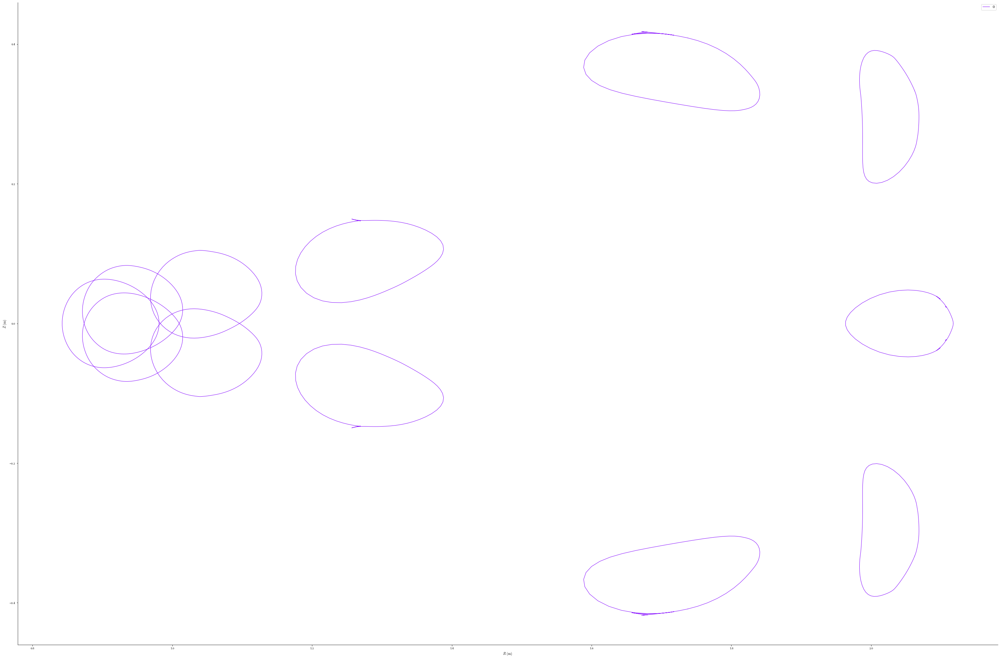

In [88]:
#fig, ax = plot_boundaries([qfm_surf, qfm_surf1], phi=12, figsize=(40, 40))
fig, ax = plot_boundaries([qfm_surf], phi=12, figsize=(40, 40))
fig.show()

In [76]:
field2_opt[1][0].X_n

Array([-0.09896246,  1.10921251,  0.00546726], dtype=float64)